# Synthetic Extracellular Spike-Train Generation

This notebook accompanies `generator.py`. The aim is to construct an illustrative extracellular-like voltage signal from **three distinct waveform templates**, randomly timed spike events, and additive measurement noise. The model is a learning exercise in stochastic simulation and time-series analysis, **not a biophysical extracellular recording model or a spike-sorting algorithm**.

The included CSV files were generated with a fixed random seed so the analysis is reproducible.

**Workflow:** define the signal model → inspect templates → load simulated observations and event annotations → plot the recording and ground-truth spike trains → check event rates and noise.

## 1. Sampling and waveform templates

Sampling at $f_s=20{,}000$ Hz gives a time step $\Delta t=1/f_s=0.05$ ms. Each synthetic spike waveform lasts $3$ ms, or **60 samples**. Three waveforms are built from sums and differences of Gaussian-shaped functions and rescaled to different amplitudes. Their shapes are deliberately distinct; the labels *Unit 1–3* do not imply particular biological cell types.

Each template can be viewed generically as a finite waveform $h_u[k]$ associated with unit $u$.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from generator import (
    DEFAULT_FS,
    DEFAULT_DURATION_S,
    DEFAULT_FIRING_RATE_HZ,
    DEFAULT_NOISE_STD,
    DEFAULT_SEED,
    make_templates,
    generate_recording,
)

PROJECT_DIR = Path.cwd()
fs = DEFAULT_FS
waveforms = make_templates(fs)
print(f"Sampling rate: {fs:,} Hz; template length: {len(waveforms[0])} samples")

Sampling rate: 20,000 Hz; template length: 60 samples


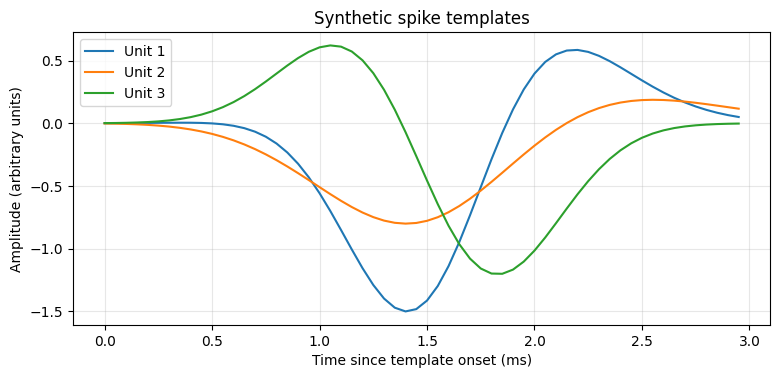

In [2]:
template_time_ms = np.arange(len(waveforms[0])) / fs * 1000
plt.figure(figsize=(9, 3.8))
for unit_id, template in enumerate(waveforms, start=1):
    plt.plot(template_time_ms, template, label=f"Unit {unit_id}")
plt.xlabel("Time since template onset (ms)")
plt.ylabel("Amplitude (arbitrary units)")
plt.title("Synthetic spike templates")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 2. Spike timing and noise

For each unit, the number of events $N_u$ is drawn from a Poisson distribution with mean $\lambda T$, where $\lambda=15$ events/s and $T=30$ s by default:

$$
N_u \sim \operatorname{Poisson}(\lambda T).
$$

Given the event count, onset samples are selected uniformly without replacement. This **approximates** a homogeneous Poisson spike train on the discrete sampling grid; the no-duplicate-sample rule distinguishes it from an exact continuous-time Poisson process.

The noise-free signal is a linear superposition of shifted templates, including overlaps:

$$
s[k]=\sum_{u=1}^{3}\sum_{j=1}^{N_u} h_u[k-k_{u,j}].
$$

White Gaussian noise is added independently to each sample:

$$
y[k]=s[k]+\eta[k],\qquad \eta[k]\sim\mathcal{N}(0,\sigma^2),\quad \sigma=0.4.
$$

Here the signal and noise amplitudes are in **arbitrary units**. The event annotations record the *start* of each inserted template, not its negative peak.

## 3. Load the generated dataset

Run `python generator.py --no-show` in this project folder to regenerate the files if they are missing. The sample times in `synthetic_spikes.csv` are stored in **seconds** (`time`), whereas the preview plots below convert time to milliseconds.

In [3]:
signal = pd.read_csv(PROJECT_DIR / "synthetic_spikes.csv")
events = pd.read_csv(PROJECT_DIR / "ground_truth_spikes.csv")

assert list(signal.columns) == ["time", "v_gen", "v_noisy"]
assert list(events.columns) == ["unit_id", "start_sample", "start_time_s"]
assert len(signal) == int(round(fs * DEFAULT_DURATION_S))

print(f"Recording: {len(signal):,} samples, {signal['time'].iloc[-1] + 1/fs:.2f} s")
print(f"Annotated spike onsets: {len(events):,}")
display(signal.head())
display(events.head())

Recording: 600,000 samples, 30.00 s
Annotated spike onsets: 1,412


,time,v_gen,v_noisy
0,0.00000,0.0,0.070905
1,0.00005,0.0,0.116493
2,0.00010,0.0,0.589445
3,0.00015,0.0,0.490414
4,0.00020,0.0,-1.146822


,unit_id,start_sample,start_time_s
0,3,311,0.01555
1,3,748,0.03740
2,3,996,0.04980
3,3,1384,0.06920
4,3,1845,0.09225


## 4. Compare noise-free and noisy recordings

Inspect a short $200$ ms window rather than plotting all 600,000 samples at once. This makes individual events and the effect of overlapping waveforms easier to see.

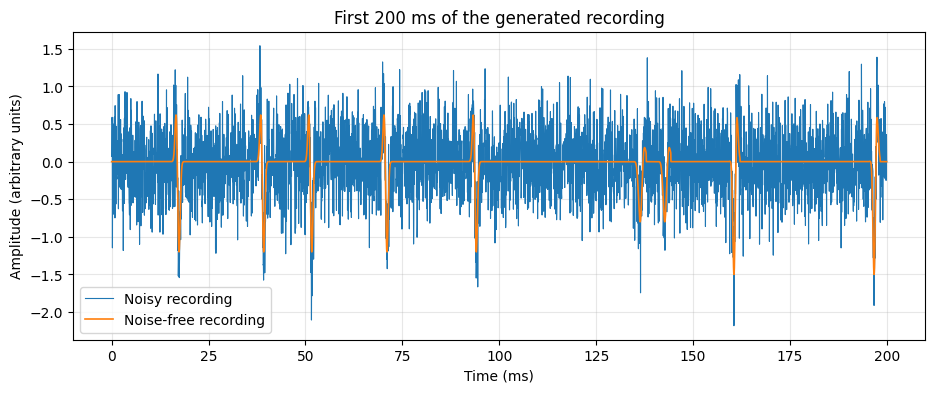

In [4]:
preview_ms = 200
preview = signal.iloc[:int(fs * preview_ms / 1000)]

plt.figure(figsize=(11, 4))
plt.plot(preview["time"] * 1000, preview["v_noisy"], lw=0.8, label="Noisy recording")
plt.plot(preview["time"] * 1000, preview["v_gen"], lw=1.2, label="Noise-free recording")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude (arbitrary units)")
plt.title("First 200 ms of the generated recording")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 5. Ground-truth event raster and realised firing rates

The annotation file stores a unit identifier, onset sample index, and onset time in seconds for each inserted event. The observed number of events varies around the target rate because the count is drawn from a Poisson distribution.

For each unit, its realised mean rate is $N_u/T$; it will not be exactly 15 Hz in a finite recording.

,event_count,realised_rate_hz
unit_id,,
1,468,15.600000
2,444,14.800000
3,500,16.666667


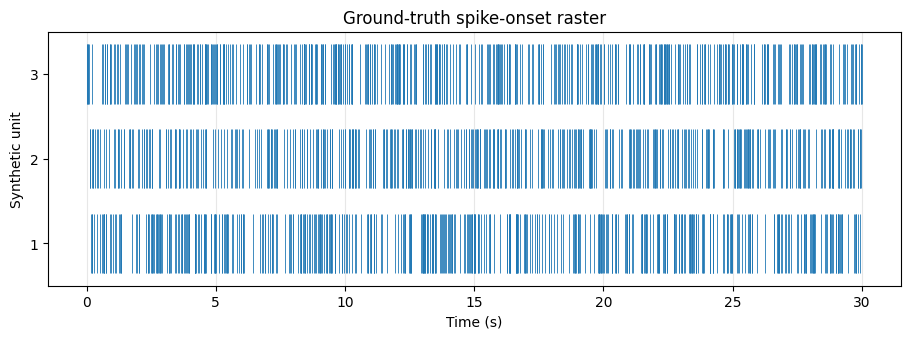

In [5]:
counts = events.groupby("unit_id").size().reindex([1, 2, 3], fill_value=0)
rates = counts / DEFAULT_DURATION_S
summary = pd.DataFrame({"event_count": counts, "realised_rate_hz": rates})
display(summary)

fig, ax = plt.subplots(figsize=(11, 3.3))
for unit_id in (1, 2, 3):
    times = events.loc[events["unit_id"] == unit_id, "start_time_s"]
    ax.vlines(times, unit_id-0.35, unit_id+0.35, lw=0.6)
ax.set(xlabel="Time (s)", ylabel="Synthetic unit", yticks=[1, 2, 3],
       ylim=(0.5, 3.5), title="Ground-truth spike-onset raster")
ax.grid(axis="x", alpha=0.3)
plt.show()

## 6. Check the injected noise and reproducibility

Because the noise-free trace is known, the injected noise can be recovered as $y[k]-s[k]$. Its sample mean should be near zero, and its standard deviation near the specified value $\sigma=0.4$.

The generator uses `numpy.random.default_rng(42)`. Running it with the same parameters and seed reproduces the dataset; changing the seed produces a different realisation.

Noise mean: -0.0004 (target 0)
Noise standard deviation: 0.4002 (target 0.4)


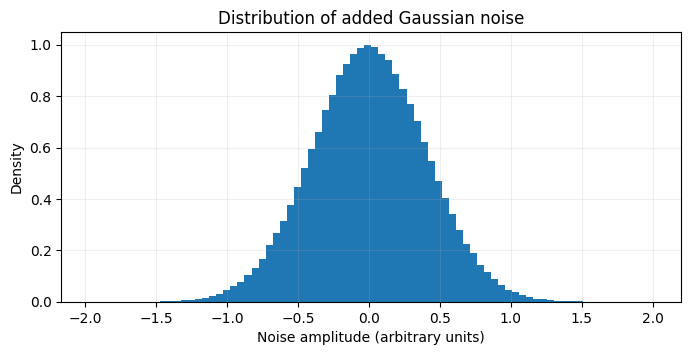

In [6]:
residual = signal["v_noisy"].to_numpy() - signal["v_gen"].to_numpy()
print(f"Noise mean: {residual.mean():.4f} (target 0)")
print(f"Noise standard deviation: {residual.std():.4f} (target {DEFAULT_NOISE_STD})")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(residual, bins=80, density=True)
ax.set(xlabel="Noise amplitude (arbitrary units)", ylabel="Density",
       title="Distribution of added Gaussian noise")
ax.grid(alpha=0.2)
plt.show()

In [7]:
# Verify that the CSVs correspond exactly to the current generator defaults.
regenerated, regenerated_events, _ = generate_recording(seed=DEFAULT_SEED)
assert np.allclose(regenerated["v_noisy"], signal["v_noisy"])
assert np.allclose(regenerated["v_gen"], signal["v_gen"])
assert regenerated_events.equals(events)
print("Reproducibility check passed: saved data and event annotations match the generator.")

Reproducibility check passed: saved data and event annotations match the generator.


## 7. Interpretation and possible extensions

The project demonstrates sampled time-series synthesis, stochastic event counts, template superposition, additive Gaussian noise, and recovery of known event annotations from a simulated dataset. Because the inserted events are known, the data can later be used to evaluate **spike detection** or **spike sorting** algorithms against ground truth.

**Not yet implemented:** threshold-based detection, waveform alignment, PCA/feature extraction, clustering, or a quantitative spike-sorting accuracy metric. Those would be separate extensions, rather than results claimed by this notebook.